In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

In [2]:
X_train = pd.read_csv("../data/selected/X_train_selected.csv")
X_val = pd.read_csv("../data/selected/X_val_selected.csv")
X_test = pd.read_csv("../data/selected/X_test_selected.csv")
y_train = pd.read_csv("../data/selected/y_train.csv").squeeze()
y_val = pd.read_csv("../data/selected/y_val.csv").squeeze()
y_test = pd.read_csv("../data/selected/y_test.csv").squeeze()
logistic_model = joblib.load("../models/logistic_regression_optimized.pkl")
decision_tree_model = joblib.load("../models/decision_tree_optimized.pkl")
random_forest_model = joblib.load("../models/random_forest_optimized.pkl")
print("Data and optimized models loaded successfully.")
print("Selected features:", list(X_train.columns))

Data and optimized models loaded successfully.
Selected features: ['n_slash', 'n_hypens', 'n_redirection', 'count', 'n_equal', 'url_length', 'n_and', 'n_dots', 'n_questionmark', 'n_at', 'n_plus', 'n_space', 'n_percent', 'n_dollar', 'n_asterisk']


In [3]:
lr_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})
lr_coefficients["Absolute_Coefficient"] = (
    lr_coefficients["Coefficient"].abs()
)
lr_coefficients = lr_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)
print(lr_coefficients.to_string(index=False))

       Feature  Coefficient  Absolute_Coefficient
         count     3.410025              3.410025
          n_at     2.021372              2.021372
n_questionmark     0.640618              0.640618
    n_asterisk     0.620023              0.620023
        n_plus    -0.543465              0.543465
       n_slash     0.501872              0.501872
      n_hypens    -0.353221              0.353221
         n_and    -0.262119              0.262119
 n_redirection    -0.214485              0.214485
      n_dollar     0.169484              0.169484
     n_percent    -0.143366              0.143366
       n_equal     0.142934              0.142934
       n_space    -0.123054              0.123054
        n_dots    -0.062001              0.062001
    url_length     0.023049              0.023049


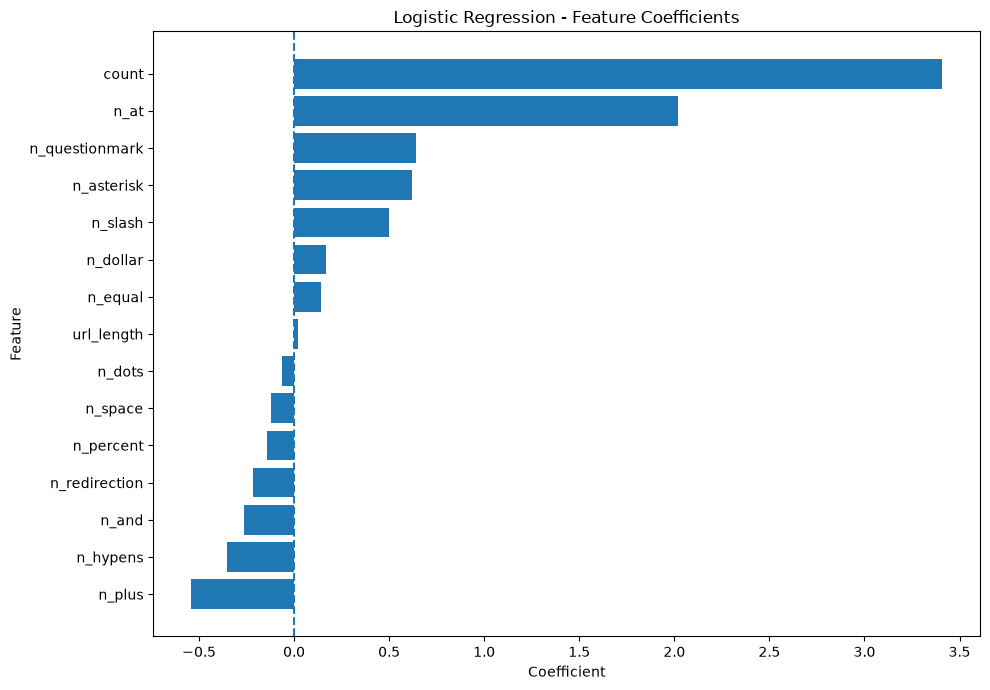

In [4]:
lr_plot = lr_coefficients.sort_values("Coefficient")
plt.figure(figsize=(10, 7))

plt.barh(
    lr_plot["Feature"],
    lr_plot["Coefficient"]
)
plt.axvline(0, linestyle="--")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression - Feature Coefficients")
plt.tight_layout()

plt.savefig(
    "../results/figures/logistic_regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [5]:
dt_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree_model.feature_importances_
})
dt_importance = dt_importance.sort_values(
    "Importance",
    ascending=False
)
print(dt_importance.to_string(index=False))

       Feature  Importance
       n_slash    0.244574
    url_length    0.212370
      n_hypens    0.135000
         count    0.111735
n_questionmark    0.108781
        n_dots    0.095794
 n_redirection    0.039955
     n_percent    0.015550
       n_equal    0.015304
        n_plus    0.008311
          n_at    0.005355
    n_asterisk    0.003950
         n_and    0.002071
       n_space    0.001250
      n_dollar    0.000000


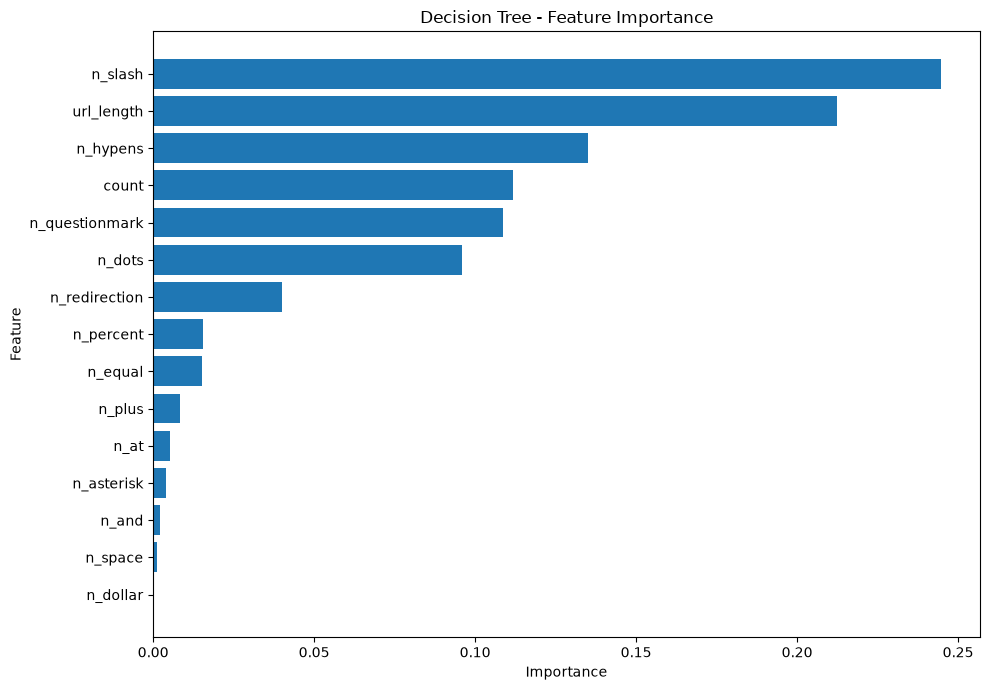

In [6]:
plt.figure(figsize=(10, 7))
plt.barh(
    dt_importance["Feature"],
    dt_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "../results/figures/decision_tree_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [7]:
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})
rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)
print(rf_importance.to_string(index=False))

       Feature  Importance
    url_length    0.262413
       n_slash    0.207430
      n_hypens    0.149634
        n_dots    0.096116
         count    0.078604
 n_redirection    0.073843
       n_equal    0.043672
     n_percent    0.024884
         n_and    0.018556
n_questionmark    0.016893
          n_at    0.015321
        n_plus    0.006650
       n_space    0.004944
    n_asterisk    0.000813
      n_dollar    0.000227


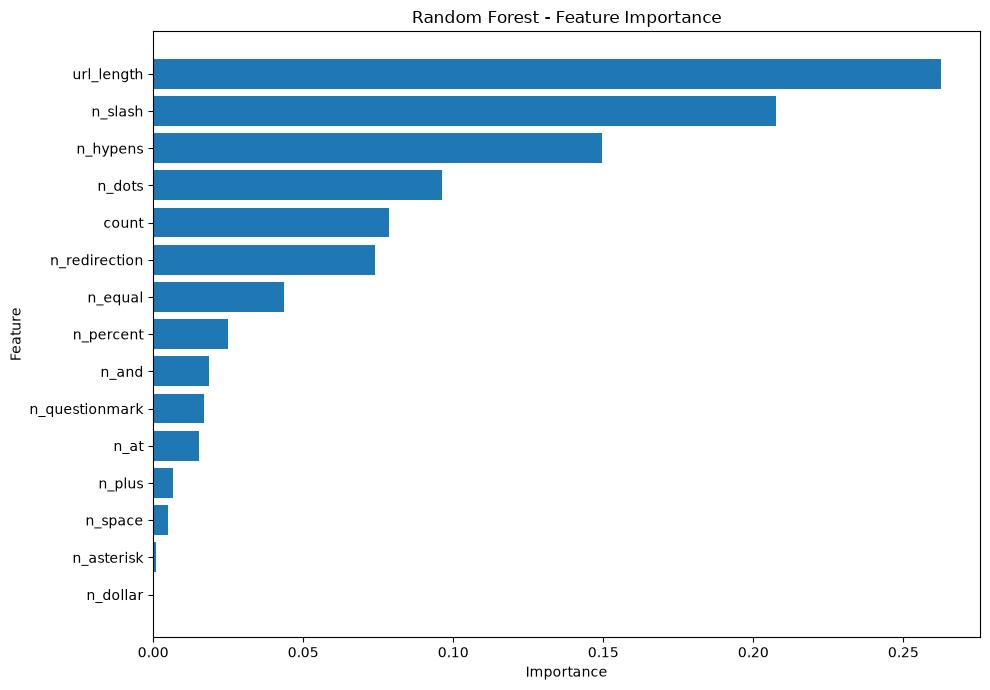

In [8]:
plt.figure(figsize=(10, 7))
plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "../results/figures/random_forest_explainability_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [9]:
lr_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Logistic_Regression": lr_coefficients["Absolute_Coefficient"].values
})
dt_importance_compare = dt_importance.rename(
    columns={"Importance": "Decision_Tree"}
)
rf_importance_compare = rf_importance.rename(
    columns={"Importance": "Random_Forest"}
)
explainability_comparison = (
    lr_importance
    .merge(
        dt_importance_compare,
        on="Feature"
    )
    .merge(
        rf_importance_compare,
        on="Feature"
    )
)
print(explainability_comparison.to_string(index=False))

       Feature  Logistic_Regression  Decision_Tree  Random_Forest
       n_slash             3.410025       0.244574       0.207430
      n_hypens             2.021372       0.135000       0.149634
 n_redirection             0.640618       0.039955       0.073843
         count             0.620023       0.111735       0.078604
       n_equal             0.543465       0.015304       0.043672
    url_length             0.501872       0.212370       0.262413
         n_and             0.353221       0.002071       0.018556
        n_dots             0.262119       0.095794       0.096116
n_questionmark             0.214485       0.108781       0.016893
          n_at             0.169484       0.005355       0.015321
        n_plus             0.143366       0.008311       0.006650
       n_space             0.142934       0.001250       0.004944
     n_percent             0.123054       0.015550       0.024884
      n_dollar             0.062001       0.000000       0.000227
    n_aste

In [10]:
explainability_comparison.to_csv(
    "../results/metrics/explainability_feature_comparison.csv",
    index=False
)
print("Explainability comparison saved successfully.")

Explainability comparison saved successfully.
